# EU short-stay accommodation (online platforms) — seasonality and foreign-share indices

Step 2 of 3 in the pipeline:

1. `Stage 1 Transform.ipynb` — raw Eurostat files → clean, tested nights (`data/transformed/tour_ce_omn12_long.csv`);
2. **this notebook** — adds the indices one by one (for each: *why* it is useful, *what* it measures, *how* it is calculated, and where it comes from) and saves **`data/ready/tour_ce_omn12_indices.csv`**, the dataset for maps and for the findings;
3. `Stage 3 Analysis.ipynb` — the findings: foreign tourism, seasonal patterns, the role of foreign guests and the factors behind seasonality.

The robustness checks of the cut-offs and classes are collected in the **appendix** at the end (R1–R4), so the definitions read without interruption. Needs pandas, numpy, scipy and matplotlib.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import fcluster, linkage        # hierarchical (Ward) clustering, step A7
from scipy.spatial.distance import pdist, squareform          # pairwise distances between profiles, step A7

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

# Load the clean dataset made by the transform notebook (step 1).
# keep_default_na=False + na_values=[""]: only truly empty cells become NaN - otherwise pandas would
# also turn text such as "NA" into missing values.
df = pd.read_csv("data/transformed/tour_ce_omn12_long.csv", encoding="utf-8-sig", keep_default_na=False, na_values=[""])

# Month is text in the CSV; make it an ordered category (January ... December, then Total) so that
# sorting, grouping and pivots follow the calendar instead of the alphabet.
MONTH_NAMES = ["January", "February", "March", "April", "May", "June", "July", "August",
               "September", "October", "November", "December"]
df["Month"] = pd.Categorical(df["Month"], categories=MONTH_NAMES + ["Total"], ordered=True)

# Countries in Eurostat's order (order of first appearance in the file) - only for tidy tables.
COUNTRIES = df["Country"].unique().tolist()
df["Country"] = pd.Categorical(df["Country"], categories=COUNTRIES, ordered=True)

# A "series" = one region x one year x one guest group = 12 monthly values + an annual total.
KEY_SERIES = ["NUTSCode", "Year", "ResidenceCountry"]
monthly = df["Month"] != "Total"                             # True on the 12 monthly rows, False on annual rows

# Series table: one row per series, the 12 months as columns in calendar order.
# observed=True: no empty "Total" column; reindex(...): guarantees exactly Jan ... Dec in that order.
wide = df[monthly].pivot_table(index=KEY_SERIES, columns="Month", values="Value", observed=True).reindex(columns=MONTH_NAMES)
# The published annual total of every series, lined up row by row with 'wide'.
annual_total = df[~monthly].set_index(KEY_SERIES)["Value"].reindex(wide.index)
# One row per region with its name and place in the hierarchy (for labels and filters).
regions = df.drop_duplicates("NUTSCode").set_index("NUTSCode")[["Region", "NUTSLevel", "ParentRegion", "Country"]]
# Extra-Regio areas (Mount Athos) are not real regions to compare with; N2 = the NUTS 2 regions without them.
extra = regions["Region"].str.startswith("Extra")
N2 = regions.index[(regions["NUTSLevel"] == 2) & ~extra]

# Chart style: colours and a helper that gives every chart the same light look.
INK, MUTED, GRIDC = "#0b0b0b", "#52514e", "#e4e3df"
def style(ax, title, ylabel=None):
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    if ylabel:
        ax.set_ylabel(ylabel, color=MUTED)
    ax.spines[["top", "right"]].set_visible(False)            # no box around the plot
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED)
    ax.grid(axis="y", color=GRIDC, lw=0.8)                    # light horizontal grid lines
    ax.set_axisbelow(True)

print(f"{len(df):,} rows; {len(wide):,} series (region x year x residence); {len(regions)} regions; years {df['Year'].min()}-{df['Year'].max()}")
print("Example of the series table - Kriti (EL43), foreign guests, 2025:")
display(wide.loc[[("EL43", 2025, "Foreign")]].assign(Total=annual_total.loc[[("EL43", 2025, "Foreign")]].values))

118,794 rows; 9,138 series (region x year x residence); 388 regions; years 2018-2025
Example of the series table - Kriti (EL43), foreign guests, 2025:


,,Month,January,February,March,April,May,June,July,August,September,October,November,December,Total
NUTSCode,Year,ResidenceCountry,,,,,,,,,,,,,
EL43,2025,Foreign,26234.0,34550.0,65699.0,442849.0,680402.0,1179257.0,1796094.0,1800820.0,1329051.0,771110.0,86346.0,42482.0,8254894


# Indices

## A1. Season75: how many months hold three-quarters of the year?

**Why.** The simplest way to say how seasonal a region is: *"three-quarters of the year's nights fall in N months"*.

**What.** **Season75** = the number of busiest months needed to reach 75% of the annual nights (1 = everything in one month; an evenly spread year needs 9). **Prc75Flag** marks those months, so you can see *which* months make the season; **CumPercentage** is the running share. **ThresholdMonth** marks months tied in nights with the month that crosses 75% — tied months have equal claim, so all of them are counted.

**How.** Sort a year's months from busiest to quietest and add them up until 75% of the annual total is reached; that month and all before it are flagged.

The 75% cut-off was tested against 50–90% (appendix R1): 60–75% agree best with the Gini index (rank correlation 0.96–0.97) and change between consecutive years in 16–19% of series; above 80% the agreement drops (0.92 at 90%) and changes become more frequent (about 20%). 75% is kept because it is the easiest to explain ("three-quarters of the nights").

Series whose published annual total is not the sum of their months get no flags — this is only *Latvija* 2024, Foreign and Total, a source error (transform notebook, step 6).

In [2]:
# Work on the monthly rows only, each with its series' annual total attached as a column.
mon = df[monthly].join(annual_total.rename("AnnualTotal"), on=KEY_SERIES)

# Within every series, order the months from busiest to quietest:
#   sort by the series key (so each series stays together), then Value descending (False),
#   then Month ascending (True) so that months with equal nights stay in calendar order.
#   kind="stable" keeps that tie order reliable.
mon = mon.sort_values(KEY_SERIES + ["Value", "Month"], ascending=[True, True, True, False, True], kind="stable")

# Running total of nights down that list, and as a % of the annual total.
mon["CumValue"] = mon.groupby(KEY_SERIES)["Value"].cumsum()
mon["CumPercentage"] = (100 * mon["CumValue"] / mon["AnnualTotal"]).round(2)

# A month is "in the season" if the share reached *before* it is still below 75%:
# this flags every month up to and including the first one that reaches 75% (the crossing month).
prev_share = 100 * (mon["CumValue"] - mon["Value"]) / mon["AnnualTotal"]
mon["_base"] = prev_share < 75

# The crossing month is the last flagged month of each series (largest running total among them).
crossing = mon[mon["_base"]].groupby(KEY_SERIES)["CumValue"].idxmax()
# Its number of nights, attached to every month of the same series.
cross_value = mon.loc[crossing.values].set_index(KEY_SERIES)["Value"].rename("_cross")
mon = mon.join(cross_value, on=KEY_SERIES)

# Ties at the break: months with exactly the same nights as the crossing month have an equal claim,
# so if there are 2+ such months, all of them are flagged (ThresholdMonth = 1) and counted.
mon["_tied"] = mon["Value"].eq(mon["_cross"])
n_tied = mon.groupby(KEY_SERIES)["_tied"].transform("sum")     # how many months share that value
mon["ThresholdMonth"] = (mon["_tied"] & (n_tied > 1)).astype("Int64")
mon["Prc75Flag"] = (mon["_base"] | (mon["ThresholdMonth"] == 1)).astype("Int64")

# Season75 = number of flagged months in the series (the same value on all its monthly rows).
mon["Season75"] = mon.groupby(KEY_SERIES)["Prc75Flag"].transform("sum").astype("Int64")

# Series whose published annual total is not the sum of their months (source error: Latvija 2024,
# Foreign and Total) and series without a positive annual total can't have a season: leave the flags empty.
broken = annual_total.ne(wide.sum(axis=1))
print("series with annual total != sum of months (left without indices):", list(broken[broken].index))
no_total = ~(mon["AnnualTotal"] > 0) | mon.set_index(KEY_SERIES).index.isin(broken[broken].index)
mon.loc[no_total, "CumPercentage"] = np.nan
mon.loc[no_total, ["Prc75Flag", "ThresholdMonth", "Season75"]] = pd.NA

# Copy the results back to the dataset; 'mon' kept df's row labels, so the join matches row by row
# (annual rows get empty values).
df = df.join(mon[["CumPercentage", "Prc75Flag", "ThresholdMonth", "Season75"]])

# Show one example, and how often ties at the break occur.
ex = mon[(mon["NUTSCode"] == "EL43") & (mon["Year"] == 2025) & (mon["ResidenceCountry"] == "Foreign")]
print("Kriti, foreign guests, 2025 - months from busiest to quietest:")
display(ex[["Month", "Value", "CumPercentage", "Prc75Flag", "ThresholdMonth", "Season75"]].reset_index(drop=True))
print(f"tied months at the break: {int((mon['ThresholdMonth'] == 1).sum())} months in "
      f"{mon.loc[mon['ThresholdMonth'] == 1].groupby(KEY_SERIES).ngroups} series")

series with annual total != sum of months (left without indices): [('LV0', 2024, 'Foreign'), ('LV0', 2024, 'Total'), ('LV00', 2024, 'Foreign'), ('LV00', 2024, 'Total')]
Kriti, foreign guests, 2025 - months from busiest to quietest:


,Month,Value,CumPercentage,Prc75Flag,ThresholdMonth,Season75
0,August,1800820,21.82,1,0,5
1,July,1796094,43.57,1,0,5
2,September,1329051,59.67,1,0,5
3,June,1179257,73.96,1,0,5
4,October,771110,83.30,1,0,5
5,May,680402,91.54,0,0,5
6,April,442849,96.91,0,0,5
7,November,86346,97.95,0,0,5
8,March,65699,98.75,0,0,5
9,December,42482,99.26,0,0,5


tied months at the break: 36 months in 18 series


## A2. Gini index: how unequal are the months?

**Why.** The most widely used seasonality measure in tourism research; it uses all 12 months, not one cut-off like Season75, so it moves smoothly.

**What.** **Gini** runs from 0 (every month has the same nights) to 0.917 (all nights in one month) — the same index that measures income inequality, applied to months instead of people. It ignores *which* months are busy (see A4).

**How.** Rank the months from quietest to busiest; Gini = 2 × covariance(nights, rank share) ÷ average monthly nights — the "covariance form" of Fernández-Morales, Cisneros-Martínez & McCabe (2016), checked below against the example patterns published by Lo Magno et al. (2017, Table 2).

**GiniMapGroup** splits regions into three roughly equal groups for maps: *Low* < 0.20, *Medium* 0.20–0.30, *High* ≥ 0.30 (the 2025 NUTS 2 tertiles are 0.195 and 0.307). The paper's own levels (0.15 / 0.25) put almost half the regions in *High*.

Sources: Fernández-Morales, Cisneros-Martínez & McCabe (2016), *Tourism Management* 56, 172–190, [doi:10.1016/j.tourman.2016.04.004](https://doi.org/10.1016/j.tourman.2016.04.004) ([free copy](https://nottingham-repository.worktribe.com/output/820323/seasonal-concentration-of-tourism-demand-decomposition-analysis-and-marketing-implications)); Fernández-Morales (2003), *Annals of Tourism Research* 30(4), [doi:10.1016/S0160-7383(03)00090-2](https://doi.org/10.1016/S0160-7383(03)00090-2).

In [3]:
T = 12   # months in a year

def rank01(y):
    """Each month's position from quietest to busiest as a fraction (1/12 ... 12/12).
    Ties keep calendar order ("stable"); argsort gives the order of the months, and writing
    1..12 into those positions turns it into ranks."""
    r = np.empty(T); r[np.argsort(y, kind="stable")] = np.arange(1, T + 1)
    return r / T

def cov(a, b):
    """Covariance of two 12-month vectors."""
    return np.mean((a - a.mean()) * (b - b.mean()))

def gini(y):
    """Gini index of 12 monthly values, covariance form: 2 x cov(nights, rank/12) / mean nights."""
    y = np.asarray(y, float)
    # Covariance of nights and position in the line-up, scaled by the average month; x2 puts it on the classic Gini scale.
    return 2 * cov(y, rank01(y)) / y.mean()

# Check against Lo Magno et al. (2017), Table 2: the Gini values they publish for example patterns.
for y, g_paper in [([0]*6 + [120] + [0]*5, .917),                       # everything in July
                   ([0]*5 + [60, 60] + [0]*5, .833),                    # June and July only
                   ([19, 0, 0, 0, 0, 1, 100, 0, 0, 0, 0, 0], .888),     # their pattern P8
                   ([2, 4, 10, 20, 16, 8, 2, 4, 10, 20, 16, 8], .356)]: # their pattern P11
    assert abs(gini(y) - g_paper) < .0015
print("Gini matches the published example values")

# Series where Gini can be computed: all 12 months present and a positive annual total.
complete = wide.notna().all(axis=1) & (annual_total > 0)

# 'idx' collects all series-level indices (one row per series, same index as 'wide').
idx = pd.DataFrame(index=wide.index)
idx.loc[complete, "Gini"] = [round(gini(r), 4) for r in wide[complete].to_numpy()]

# Where do the NUTS 2 regions split into three equal groups (tertiles) in 2025? -> basis of GiniMapGroup.
r25 = idx.reset_index()
r25 = r25[r25["NUTSCode"].isin(N2) & (r25["Year"] == 2025) & (r25["ResidenceCountry"] == "Total")]
print("NUTS 2 regions, 2025: Gini tertiles", np.percentile(r25["Gini"].dropna(), [100 / 3, 200 / 3]).round(3))

Gini matches the published example values
NUTS 2 regions, 2025: Gini tertiles [0.195 0.307]


## A3. Minimum-volume rule: only judge seasonality where there are enough nights

**Why.** With a few hundred nights a year, one booking moves a month's share by several points — Liechtenstein's domestic guests (≈ 300 nights a year) come out with a "season" scattered over random months.

**What.** **VolumeOK** = 1 if a region-year-residence has at least **10,000 nights** (and all 12 months, and a published annual total equal to the sum of its months). The seasonality indices below are given only where VolumeOK = 1.

**How.** The threshold comes from the data: below 10,000 nights a year, the Gini index and Season75 jump around from year to year much more than for larger series (table: typical change between consecutive years, 2023–2025). The evidence below the threshold is thin — only 29 year-pairs (17 + 12) — so 10,000 is a sensible floor rather than a precisely estimated break; between 10,000 and 100,000 nights the series already behave like large ones.

**Rule of thumb for reading Gini:** above the threshold, a region's Gini typically moves about 0.01 from one year to the next and 90% of moves are below about 0.025 — so differences under 0.02–0.03, between regions or between years, are within normal movement.

In [4]:
MIN_NIGHTS = 10_000                                            # the underscore is only a digit separator

# VolumeOK: all 12 months present, positive total (both in 'complete') and at least 10,000 nights a year.
# ~broken: also not where the published annual total differs from the sum of the months (A1).
volume_ok = complete & (annual_total >= MIN_NIGHTS) & ~broken
idx["VolumeOK"] = volume_ok.astype(int)

# Evidence for the threshold: how much the Gini index and Season75 change from one year to the next,
# by size of the series. Season75 is one value per series - take it from the monthly rows.
s75 = df[monthly].groupby(KEY_SERIES)["Season75"].first().reindex(idx.index)
ev = pd.DataFrame({"nights": annual_total, "Gini": idx["Gini"], "Season75": s75.astype(float)})[complete].reset_index()
ev = ev.sort_values(["NUTSCode", "ResidenceCountry", "Year"])  # each region + guest group in year order
grp = ev.groupby(["NUTSCode", "ResidenceCountry"])
# Change from the previous year (absolute), and which year that was.
ev["dGini"], ev["dS75"], ev["prev"] = grp["Gini"].diff().abs(), grp["Season75"].diff().abs(), grp["Year"].shift()
# Only consecutive years from 2023 on (2022->2023, 2023->2024, 2024->2025): leaves out the COVID years.
ev = ev[(ev["Year"] >= 2023) & (ev["prev"] == ev["Year"] - 1)].copy()
# Size classes of the series.
ev["annual nights"] = pd.cut(ev["nights"], [0, 3e3, 1e4, 3e4, 1e5, 1e6, np.inf],
                             labels=["< 3k", "3k-10k", "10k-30k", "30k-100k", "100k-1m", "> 1m"])
# Typical (median) year-to-year change of Gini, and how often Season75 changes, per size class.
display(ev.groupby("annual nights", observed=True)
          .agg(pairs=("dGini", "size"), typical_change_Gini=("dGini", "median"),
               share_with_Season75_change=("dS75", lambda s: round((s > 0).mean(), 2))).round(3))

# Apply the rule: no Gini for unreliable series ...
idx.loc[~volume_ok, "Gini"] = np.nan
# ... and the three map groups (right=False: 0.20 belongs to Medium, 0.30 to High).
idx["GiniMapGroup"] = pd.cut(idx["Gini"], bins=[-np.inf, 0.20, 0.30, np.inf], right=False, labels=["Low", "Medium", "High"])

# Which regions fall below the rule (some examples).
low = idx[~volume_ok].reset_index().merge(regions, left_on="NUTSCode", right_index=True)
print(f"{(~volume_ok).sum()} of {len(idx):,} series below the rule, e.g.:",
      sorted(low["Region"].unique())[:12])

,pairs,typical_change_Gini,share_with_Season75_change
annual nights,,,
< 3k,17,0.188,0.65
3k-10k,12,0.086,0.42
10k-30k,39,0.020,0.18
30k-100k,115,0.021,0.24
100k-1m,1353,0.014,0.18
> 1m,1890,0.012,0.15


112 of 9,138 series below the rule, e.g.: ['Ciudad de Ceuta', 'Ciudad de Melilla', 'Dytiki Makedonia', 'Extra-Regio NUTS 1', 'Extra-Regio NUTS 2', 'Guyane', 'Latvija', 'Liechtenstein', 'Mayotte', 'Mazowiecki regionalny', 'Molise', 'Opolskie']


## A3b. Seasonality percentile: Gini on a 0–100 scale

**Why.** A Gini of 0.39 means little to most readers; "more seasonal than 85% of regions" does.

**What.** **SeasonalityPercentile** — the share of comparable units with a *lower* Gini index, 0 (least seasonal) to 100 (most seasonal). Comparable = same NUTS level, same year and same guest group: regions are ranked against regions, countries against countries; domestic guests against the domestic guests of other regions.

**How.** Rank the Gini values within each peer group; percentile = (number of peers with a lower Gini) ÷ (number of peers − 1) × 100, rounded. Only series with VolumeOK = 1 are ranked; Extra-Regio is left out.

In [5]:
# Peer group of every series: NUTS level, year and guest group.
codes = idx.index.get_level_values("NUTSCode")
peer = [np.asarray(codes.map(regions["NUTSLevel"])),
        np.asarray(idx.index.get_level_values("Year")),
        np.asarray(idx.index.get_level_values("ResidenceCountry"))]
# Gini without Extra-Regio (Mount Athos and similar), which is not a real region to compare with.
g_rank = idx["Gini"].where(~np.asarray(codes.map(extra), bool))
lower = g_rank.groupby(peer).rank(method="min") - 1          # how many peers have a lower Gini
n_peers = g_rank.groupby(peer).transform("count")            # how many peers have a Gini at all
idx["SeasonalityPercentile"] = (100 * lower / (n_peers - 1)).round().astype("Int64")

# Examples: all guests, 2025.
ex = idx.reset_index().merge(regions, left_on="NUTSCode", right_index=True)
ex = ex[(ex["Year"] == 2025) & (ex["ResidenceCountry"] == "Total")
        & ex["NUTSCode"].isin(["HR", "ES", "PT15", "HR03", "AT32", "FR10", "ES70"])]
ex[["Region", "NUTSLevel", "Gini", "SeasonalityPercentile"]].sort_values(["NUTSLevel", "Gini"], ascending=[True, False])

,Region,NUTSLevel,Gini,SeasonalityPercentile
5285,Croatia,0,0.6116,100
3437,Spain,0,0.2051,33
5357,Jadranska Hrvatska,2,0.6370,100
8171,Algarve,2,0.3858,83
263,Salzburg,2,0.3142,70
4325,Ile de France,2,0.1115,5
4061,Canarias,2,0.0955,2


## A4. Timing: one season, two seasons, and when

**Why.** Gini says *how much* a year is concentrated, not *when*. A ski-and-summer region (Salzburg) and a one-peak beach region can have the same Gini, although the ski region's two seasons fill each other's off-season.

**What.**
* **SeasonShape** — *One season*, *Two seasons* (separate peaks, e.g. winter + summer) or *No clear season* (Gini < 0.15, the "low" level of Fernández-Morales et al. 2016).
* **SeasonCentre** — where the year's nights are centred on the calendar circle, as a month position (each month sits at its whole number: 1.0 = January, 7.0 = July, 12.0 = December, so 7.5 = halfway between July and August and 12.5 = between December and January; cyclic, values 1.0–12.99), and **SeasonCentreMonth**, the nearest month — given only for one-season years, because a two-season "centre" falls between the seasons.

**How.** Two published measures are compared:
* **S_R** (Lo Magno, Ferrante & De Cantis 2017): the minimum effort, counted in months of distance around the calendar, needed to move nights from busy to quiet months until every month is equal, scaled 0–1. Two peaks far apart need little moving, so S_R rates them as less seasonal than Gini does.
* **PCD** (Zhang & Qian 2003): treat each month as a direction on a clock and its nights as the length of an arrow; the combined arrow points to the season centre, and its length (0–1) shows how concentrated the year is around one direction. Opposite peaks cancel out, so PCD is low for two-season years.

For a single peak, PCD ≈ 1.1–1.2 × S_R; for two equal opposite peaks ≈ 0.5 × S_R. **Rule of this analysis (not from the literature): PCD ÷ S_R < 0.8 = two seasons.** Both functions are checked against Table 2 of Lo Magno et al. (2017).

Sources: Lo Magno, Ferrante & De Cantis (2017), *Mathematical Social Sciences* 88, 55–65, [doi:10.1016/j.mathsocsci.2017.05.002](https://doi.org/10.1016/j.mathsocsci.2017.05.002); Zhang, L. & Qian, Y. (2003), *Acta Meteorologica Sinica* 17(2), 146–163.

In [6]:
THETA = 2 * np.pi * np.arange(T) / T     # each month's angle on the calendar circle: January 0, February 30 degrees, ...

def s_r(y):
    """S_R (Lo Magno et al. 2017) with the circular distance between months.
    The minimum 'moving effort' to make all months equal has a closed form on a circle:
    take the running sum of (month - average month); the effort is the total distance of those
    running sums from their median. Dividing by 3 x annual total (the maximum, for 12 months)
    scales it to 0-1."""
    y = np.asarray(y, float)
    d = np.cumsum(y - y.mean())
    return np.abs(d - np.median(d)).sum() / (3 * y.sum())

def pcd_centre(y):
    """PCD and season centre (Zhang & Qian 2003): add up the months as arrows on a clock,
    each as long as its nights. Arrow length / total nights = PCD (0-1);
    its direction = the season centre, as a month position: 1.0 = January ... 12.0 = December
    (each month at its whole number; 12.5 = between December and January)."""
    y = np.asarray(y, float)
    cx, sy = (y * np.cos(THETA)).sum(), (y * np.sin(THETA)).sum()          # the combined arrow
    return np.hypot(cx, sy) / y.sum(), (np.arctan2(sy, cx) % (2 * np.pi)) / (2 * np.pi) * T + 1

# Check against Lo Magno et al. (2017), Table 2 (S_R and PCD of their example patterns).
for y, sr_p, pcd_p in [([0]*6 + [120] + [0]*5, 1.000, 1.000),                           # all in July
                       ([0]*5 + [60, 60] + [0]*5, .833, .966),                           # June + July
                       ([0]*3 + [60, 0, 0, 0, 0, 60, 0, 0, 0], .500, .259),              # April + September
                       ([2, 4, 10, 20, 16, 8, 2, 4, 10, 20, 16, 8], .189, .000)]:        # two identical halves
    assert abs(s_r(y) - sr_p) < .0015 and abs(pcd_centre(y)[0] - pcd_p) < .0015
print("S_R and PCD match the published example values")

# Compute S_R, PCD and the centre for every reliable series.
Xok = wide[volume_ok].to_numpy()
pc = np.array([pcd_centre(r) for r in Xok])                 # column 0 = PCD, column 1 = centre
idx.loc[volume_ok, "SR"] = [round(s_r(r), 4) for r in Xok]
idx.loc[volume_ok, "PCD"] = pc[:, 0].round(4)

# Season shape: low Gini -> no clear season; otherwise compare PCD with S_R
# (about 1.2 for one peak, about 0.5 for two opposite peaks; our cut-off 0.8).
ratio = idx["PCD"] / idx["SR"]
shape = np.where(idx["Gini"] < 0.15, "No clear season", np.where(ratio >= 0.8, "One season", "Two seasons"))
idx["SeasonShape"] = pd.Categorical(pd.Series(shape, index=idx.index).where(volume_ok),     # empty if not VolumeOK
                                    categories=["One season", "Two seasons", "No clear season"])

# Season centre only for one-season years. (c - 1) % 12 + 1 wraps a rounded 13.0 back to 1.0 (January).
one = idx["SeasonShape"] == "One season"
centre = pd.Series(pc[:, 1], index=wide.index[volume_ok]).round(2)
idx.loc[one, "SeasonCentre"] = (centre[one[volume_ok].values] - 1) % 12 + 1
# Nearest month name: 7.29 -> July, 7.6 -> August, 12.8 -> January (cyclic).
idx["SeasonCentreMonth"] = idx["SeasonCentre"].map(lambda c: MONTH_NAMES[(int(np.floor(c + 0.5)) - 1) % 12] if pd.notna(c) else np.nan)

# Examples: Kriti, Croatian coast, Tirol, Salzburg, Paris, Canarias, Rhône-Alpes (all guests, 2025).
show = idx.reset_index().merge(regions, left_on="NUTSCode", right_index=True)
show = show[(show["Year"] == 2025) & (show["ResidenceCountry"] == "Total")
            & show["NUTSCode"].isin(["EL43", "HR03", "AT33", "AT32", "FR10", "ES70", "FRK2"])]
show[["Region", "Gini", "SR", "PCD", "SeasonShape", "SeasonCentreMonth"]]

S_R and PCD match the published example values


,Region,Gini,SR,PCD,SeasonShape,SeasonCentreMonth
263,Salzburg,0.3142,0.1602,0.0551,Two seasons,NaN
287,Tirol,0.2900,0.1614,0.1155,Two seasons,NaN
3143,Kriti,0.5207,0.5146,0.6379,One season,July
4061,Canarias,0.0955,0.0630,0.0685,No clear season,NaN
4325,Ile de France,0.1115,0.0971,0.1171,No clear season,NaN
5021,Rhône-Alpes,0.2478,0.1196,0.0480,Two seasons,NaN
5357,Jadranska Hrvatska,0.6370,0.6375,0.7655,One season,July


## A5. Foreign share

**Why.** The first dimension of the research: how much a region depends on guests from abroad.

**What.** **PrcForeign** = foreign nights as % of all nights, for each region, year and month (and the annual total); the same value is written on the Domestic, Foreign and Total rows. **ForeignGroup**: *Mainly domestic* < 40%, *Mixed* 40–70%, *Mainly foreign* ≥ 70%.

**How.** Foreign ÷ Total (Eurostat's total over all guests). The 40% / 70% cuts sit close to the tertiles and to the natural breaks (Jenks) of the regions' annual shares (table) and are kept fixed so groups stay comparable across years.

In [7]:
# A "cell" = one region x year x month (incl. the annual Total); put the three guest groups side by side.
CELL = ["NUTSCode", "Year", "Month"]
piv = df.pivot_table(index=CELL, columns="ResidenceCountry", values="Value", aggfunc="sum", observed=True)
# Foreign / Total x 100; .where(Total > 0) avoids dividing by zero (months with no nights stay empty).
piv["PrcForeign"] = (100 * piv["Foreign"] / piv["Total"].where(piv["Total"] > 0)).round(2)
# Where Eurostat's Total differs from Domestic + Foreign by more than 1%, the share is not defined
# (source error: Latvija 2024, October-December and the annual total) - leave it empty.
gap = (piv["Total"] - piv["Domestic"] - piv["Foreign"]).abs()
bad_cell = piv[["Domestic", "Foreign", "Total"]].notna().all(axis=1) & (gap > 0.01 * piv["Total"])
piv.loc[bad_cell, "PrcForeign"] = np.nan
print("cells with Total != Domestic + Foreign (no PrcForeign):", sorted(set(bad_cell[bad_cell].index.droplevel("Month"))))
# Write the share on all three residence rows of that cell.
df = df.join(piv["PrcForeign"], on=CELL)
# Three groups; right=False: exactly 40 goes to Mixed, exactly 70 to Mainly foreign.
df["ForeignGroup"] = pd.cut(df["PrcForeign"], bins=[-np.inf, 40, 70, np.inf], right=False,
                            labels=["Mainly domestic", "Mixed", "Mainly foreign"])

def jenks3(values):
    """Natural breaks into 3 classes: tries every pair of cut points and keeps the one with the
    smallest total within-class variation (sum of squared differences from each class mean)."""
    v = np.sort(np.asarray(values, float)); cs, cs2 = np.cumsum(v), np.cumsum(v * v)
    # variation of v[i:j], from cumulative sums (fast)
    sse = lambda i, j: (cs2[j - 1] - (cs2[i - 1] if i else 0)) - (cs[j - 1] - (cs[i - 1] if i else 0)) ** 2 / (j - i)
    _, a, b = min((sse(0, a) + sse(a, b) + sse(b, len(v)), a, b) for a in range(1, len(v) - 1) for b in range(a + 1, len(v)))
    return v[a], v[b]                                          # first value of class 2 and of class 3

# Compare the fixed 40 / 70 cuts with tertiles and natural breaks of the 2025 annual shares.
ann_f = df[(df["Month"] == "Total") & (df["ResidenceCountry"] == "Total")]
rows = []
for lvl in (1, 2):
    x_ = ann_f[(ann_f["NUTSLevel"] == lvl) & (ann_f["Year"] == 2025) & ~ann_f["NUTSCode"].map(extra)]["PrcForeign"].dropna()
    t1, t2 = np.percentile(x_, [100 / 3, 200 / 3]); j1, j2 = jenks3(x_)
    rows.append({"NUTS level": lvl, "regions": len(x_), "tertiles": f"{t1:.1f} / {t2:.1f}", "natural breaks": f"{j1:.1f} / {j2:.1f}"})
pd.DataFrame(rows)

cells with Total != Domestic + Foreign (no PrcForeign): [('LV0', 2024), ('LV00', 2024)]


,NUTS level,regions,tertiles,natural breaks
0,1,95,40.6 / 71.7,43.8 / 70.4
1,2,258,40.4 / 67.8,40.0 / 66.9


## A6. Do foreign guests add to or reduce seasonality?

**Why.** A region can be very foreign *and* very seasonal without the foreigners causing it; this index separates the two guest groups' roles.

**What.** **RMEForeign** — how much the region's Gini index would change, relatively, if foreign demand grew a little with its current monthly pattern. Negative = foreign guests smooth the year; positive = they sharpen it. **ForeignSeasonEffect**: *Smoothing* (≤ −0.02), *Small or unclear* (between −0.02 and 0.02), *Sharpening* (≥ 0.02) — the classes of Fernández-Morales et al. (2016), who call them favourable / somewhat favourable / unfavourable.

**How firm are the classes?** The ±0.02 band is about as wide as a region's normal year-to-year movement of RMEForeign (median change 0.013–0.018), so *Small or unclear* means the effect cannot be told apart from zero, not that it is zero. *Sharpening* and *Smoothing* are fairly stable from year to year; the class shares hardly change between ±0.01 and ±0.03 (appendix R2). RMEForeign describes the effect of a *small* change in foreign demand; how much of today's seasonality lies in foreign guests' timing is ForeignTimingEffect (A6b). In the findings, ForeignTimingEffect is the headline measure and RMEForeign is reported in an appendix.

**How.** The Gini index of all nights (domestic + foreign) is split into the two groups' contributions: each group's share of nights × its own Gini × its "Gini correlation" with the total (negative when the group comes in the region's quiet months). The relative marginal effect RME = contribution ÷ total Gini − share (Lerman & Yitzhaki 1985, applied to tourism by Fernández-Morales et al. 2016, eqs. A.5–A.9). Calculated where domestic and foreign guests together have at least 10,000 nights and neither series is broken (A1: not Latvija 2024).

In [8]:
# Domestic and foreign series tables (rows = region x year), kept only where both exist.
wd = wide.xs("Domestic", level="ResidenceCountry"); wf = wide.xs("Foreign", level="ResidenceCountry")
both = wd.index.intersection(wf.index)
wd, wf = wd.loc[both], wf.loc[both]
# Same minimum-volume rule, applied to domestic + foreign together.
bad_dec = (broken.xs("Domestic", level="ResidenceCountry").reindex(both, fill_value=False)
           | broken.xs("Foreign", level="ResidenceCountry").reindex(both, fill_value=False))
ok_dec = ((wd.sum(axis=1) + wf.sum(axis=1)) >= MIN_NIGHTS) & ~bad_dec

dec_rows = []
for key, xd, xf in zip(both[ok_dec.values], wd[ok_dec].to_numpy(), wf[ok_dec].to_numpy()):
    y = xd + xf                                                # all nights of the region-year
    gy, fy = gini(y), rank01(y)                                # its Gini, and each month's position in it
    # Foreign guests: share of nights (S), own Gini (G), Gini correlation with the total (Gamma)
    #   Gamma = cov(foreign nights, position of the month in the TOTAL ranking)
    #         / cov(foreign nights, position of the month in the FOREIGN ranking)
    #   = 1 if foreign guests are busiest in the region's busiest months, negative if in its quiet months.
    sF, gF, c_own = xf.sum() / y.sum(), gini(xf), cov(xf, rank01(xf))
    gamF = cov(xf, fy) / c_own if c_own > 0 else np.nan
    # The same for domestic guests (only needed for the check below).
    sD, gD, cD = xd.sum() / y.sum(), (gini(xd) if xd.sum() > 0 else 0.0), cov(xd, rank01(xd))
    gamD = cov(xd, fy) / cD if cD > 0 else 0.0
    # Check: S x Gamma x G of both groups adds up exactly to the total Gini (the decomposition holds).
    assert abs(sD * gamD * gD + (sF * gamF * gF if not np.isnan(gamF) else 0) - gy) < 1e-9
    # Relative marginal effect of foreign guests: their share of the Gini minus their share of nights.
    dec_rows.append((*key, sF * gamF * gF / gy - sF if gy > 0 else np.nan))

dec = pd.DataFrame(dec_rows, columns=["NUTSCode", "Year", "RMEForeign"])
dec["RMEForeign"] = dec["RMEForeign"].round(4)
# Classes of Fernández-Morales et al. (2016), applied to the stored (rounded) value.
dec["ForeignSeasonEffect"] = pd.Categorical(
    np.select([dec["RMEForeign"] <= -0.02, dec["RMEForeign"] >= 0.02], ["Smoothing", "Sharpening"], "Small or unclear"),
    categories=["Smoothing", "Small or unclear", "Sharpening"])
dec.loc[dec["RMEForeign"].isna(), "ForeignSeasonEffect"] = np.nan
print(f"{len(dec):,} region-years decomposed (contributions add up to the Gini index in every case)")
print(dec["ForeignSeasonEffect"].value_counts())

3,031 region-years decomposed (contributions add up to the Gini index in every case)
ForeignSeasonEffect
Sharpening          1634
Small or unclear     727
Smoothing            670
Name: count, dtype: int64


## A6b. Foreign timing effect: how much of the seasonality lies in foreign guests' timing

**Why.** RMEForeign (A6) looks ahead at a *small* change in foreign demand. To say how much foreign guests shape *today's* season, compare the actual year with one in which foreign guests travel like domestic guests.

**What.** **ForeignTimingEffect** = Gini of all nights − Gini if foreign guests kept their number of nights but spread them over the year like the region's domestic guests, in Gini points. Positive = foreign timing makes the year more seasonal; negative = less seasonal; 0 = foreign guests travel like domestic guests. **ForeignTimingClass**: *Adds* (> +0.03), *No clear effect* (−0.03 to +0.03), *Reduces* (< −0.03) — 0.03 is the upper end of the normal year-to-year movement of the Gini index (A3).

**How.** The foreign monthly profile is replaced by the domestic one, scaled to the foreign annual nights. Both guest groups need all 12 months and at least 10,000 nights a year (and not the broken Latvija 2024 series). This is an **accounting comparison, not a causal effect**: it shows how much of the seasonality is *in* foreign demand, not what would happen if foreign guests changed their behaviour. Why foreign guests travel at different times than domestic guests cannot be tested with these data (no countries of origin). It is given in Gini points rather than as a % of Gini, which would exaggerate the effect in cities with almost no season (the weakness of RMEForeign).

In [9]:
# ForeignTimingEffect for every region-year (all NUTS levels) where both guest groups have 12 months and >= 10,000 nights.
# Reuses the domestic and foreign series tables (wd, wf, rows 'both') and the broken-series mask (bad_dec) of A6.
fte = []
for k, xd, xf, bad in zip(both, wd.to_numpy(float), wf.to_numpy(float), bad_dec.to_numpy()):
    if bad or np.isnan(xd).any() or np.isnan(xf).any() or min(xd.sum(), xf.sum()) < MIN_NIGHTS:
        continue
    # actual Gini minus Gini with the foreign nights spread like the domestic ones
    fte.append((*k, gini(xd + xf) - gini(xd + xf.sum() * xd / xd.sum())))
fte = pd.DataFrame(fte, columns=["NUTSCode", "Year", "ForeignTimingEffect"])
fte["ForeignTimingEffect"] = fte["ForeignTimingEffect"].round(4)
fte["ForeignTimingClass"] = pd.Categorical(
    np.select([fte["ForeignTimingEffect"] > 0.03, fte["ForeignTimingEffect"] < -0.03], ["Adds", "Reduces"], "No clear effect"),
    categories=["Reduces", "No clear effect", "Adds"])

# NUTS 2 regions: classes by year, and how stable the ranking is.
n2_ = fte[fte["NUTSCode"].isin(N2)]
print(f"{len(fte):,} region-years; {int((n2_['Year'] == 2025).sum())} NUTS 2 regions in 2025")
print("NUTS 2 regions per class, by year (%):")
display((100 * pd.crosstab(n2_["Year"], n2_["ForeignTimingClass"], normalize="index")).round(0))
pv_ = n2_.pivot(index="NUTSCode", columns="Year", values="ForeignTimingEffect")
print("rank correlation of ForeignTimingEffect 2024 -> 2025:", round(pv_[2024].corr(pv_[2025], method="spearman"), 2))
ex_ = n2_[n2_["Year"] == 2025].merge(regions[["Region"]], left_on="NUTSCode", right_index=True)
pd.concat([ex_.nlargest(5, "ForeignTimingEffect"), ex_.nsmallest(5, "ForeignTimingEffect")])[["Region", "ForeignTimingEffect", "ForeignTimingClass"]]

2,971 region-years; 254 NUTS 2 regions in 2025
NUTS 2 regions per class, by year (%):


ForeignTimingClass,Reduces,No clear effect,Adds
Year,,,
2018,15.0,48.0,37.0
2019,15.0,47.0,38.0
2020,26.0,54.0,20.0
2021,23.0,51.0,25.0
2022,15.0,47.0,38.0
2023,14.0,48.0,38.0
2024,11.0,50.0,39.0
2025,11.0,48.0,41.0


rank correlation of ForeignTimingEffect 2024 -> 2025: 0.96


,Region,ForeignTimingEffect,ForeignTimingClass
1067,Kentriki Makedonia,0.3215,Adds
1059,"Anatoliki Makedonia, Thraki",0.2945,Adds
2922,Zahodna Slovenija,0.2833,Adds
1735,Panonska Hrvatska,0.1986,Adds
1094,Thessalia,0.1881,Adds
2649,Algarve,-0.1875,Reduces
1326,Canarias,-0.1541,Reduces
1278,Comunitat Valenciana,-0.1272,Reduces
2060,Provincia Autonoma di Bolzano/Bozen,-0.1234,Reduces
2004,Puglia,-0.1224,Reduces


## A7. Season pattern: one label for the shape of the year

**Why.** A single, readable label for maps and tooltips that combines *how many* seasons a region has, *when* they are and *how sharp* the summer peak is.

**What.** **SeasonPattern** — per region, year and guest group (like the other indices), five patterns:

| Pattern | Rule |
|---|---|
| *Mild or no season* | no clear season (Gini < 0.15) — checked first; or, after all the rules below, July–August below 1.5 × an average month |
| *Winter-based seasons* | two seasons (SeasonShape), or one season centred November–March |
| *Summer season + winter shoulder* | one summer season, but December–February at least as busy as an average month |
| *Strong summer season* | July–August at least 2.5 × an average month |
| *Summer season* | July–August 1.5–2.5 × an average month |

The rules are checked from top to bottom and the first one that applies gives the pattern, so e.g. a region with two seasons is *Winter-based* even if its summer is strong. *Mild or no season* is both the first test (no clear season) and what is left when no other rule applies (a flat summer).

**How.** From the indices above (SeasonShape, SeasonCentreMonth) and the monthly *seasonal factors* (month ÷ average month, so 1 = an average month). The cut-offs 1 and 2.5 / 1.5 are the ones used to name the clusters of Ferrante, Lo Magno & De Cantis (2018).

**How firm.** *Strong summer season*, *Mild or no season* and *Winter-based seasons* are stable from year to year and distinct in the monthly profiles; *Summer season* is the broad middle group. *Summer season + winter shoulder* is small (7 NUTS 2 regions in 2025) and sensitive to its winter cut-off: read it as "summer regions with some winter business", not as a firm group. A data-driven clustering finds the same groups for 83% of regions (appendix R3, R4).


SeasonPattern,Strong summer season,Summer season,Summer season + winter shoulder,Winter-based seasons,Mild or no season
"NUTS 2 regions, 2025",49,119,7,19,64


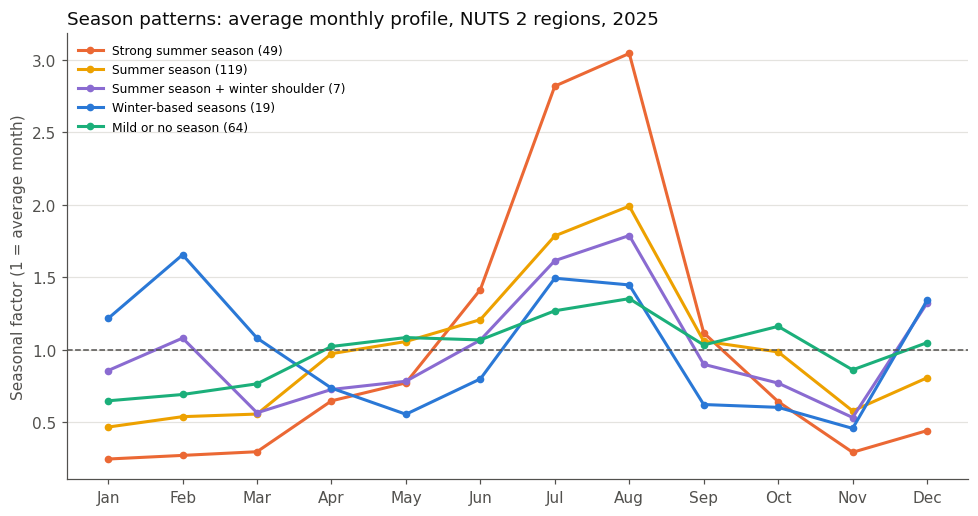

In [10]:
# Seasonal factors of every reliable series: month / average month (1 = an average month).
fac = wide[volume_ok].div(wide[volume_ok].sum(axis=1), axis=0) * T
summer_f = fac[["July", "August"]].mean(axis=1)                    # height of the summer peak
winter_f = fac[["December", "January", "February"]].mean(axis=1)   # how busy the winter is
shape = idx.loc[volume_ok, "SeasonShape"]
winter_centre = idx.loc[volume_ok, "SeasonCentreMonth"].isin(["November", "December", "January", "February", "March"])

PATTERNS = ["Strong summer season", "Summer season", "Summer season + winter shoulder", "Winter-based seasons", "Mild or no season"]
# np.select takes the first rule that is true, so the order of the rules matters (see the table above):
# 'Mild or no season' is both the first rule (Gini < 0.15) and the default when no other rule applies.
pattern = np.select(
    [shape == "No clear season", (shape == "Two seasons") | winter_centre, winter_f >= 1, summer_f >= 2.5, summer_f >= 1.5],
    ["Mild or no season", "Winter-based seasons", "Summer season + winter shoulder", "Strong summer season", "Summer season"],
    "Mild or no season")
# Back to all series (empty where VolumeOK = 0), as an ordered category.
idx["SeasonPattern"] = pd.Categorical(pd.Series(pattern, index=fac.index).reindex(idx.index), categories=PATTERNS)

# NUTS 2 regions, all guests, 2025: how many per pattern, and their average monthly profile.
sel = [k for k in fac.index if k[1] == 2025 and k[2] == "Total" and regions.at[k[0], "NUTSLevel"] == 2]
p25 = idx.loc[sel, "SeasonPattern"]
display(p25.value_counts().reindex(PATTERNS).rename("NUTS 2 regions, 2025").to_frame().T)

PATTERN_COLOR = dict(zip(PATTERNS, ["#eb6834", "#eda100", "#8a6bd1", "#2a78d6", "#1baf7a"]))
fig, ax = plt.subplots(figsize=(9, 4.8), dpi=110)
for p in PATTERNS:
    rows = fac.loc[p25[p25 == p].index]
    if len(rows):
        ax.plot(np.arange(12), rows.mean().values, color=PATTERN_COLOR[p], lw=2, marker="o", ms=4, label=f"{p} ({len(rows)})")
ax.axhline(1, color=MUTED, lw=1, ls="--")
ax.set_xticks(np.arange(12), [m[:3] for m in MONTH_NAMES])
style(ax, "Season patterns: average monthly profile, NUTS 2 regions, 2025", "Seasonal factor (1 = average month)")
ax.legend(frameon=False, loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

## A8. Geography groups: urban, coastal, mountain, island

**Why.** To test *where* seasonal and foreign-dependent tourism happens, regions are grouped by their geography.

**What.** The clean dataset carries each region's geography as shares of its **residents** (transform notebook, step 4b, from Eurostat's municipality data and NUTS 3 typologies). Here they become three groups each:
* **UrbanGroup** — *Predominantly urban* (rural share ≤ 20%), *Intermediate*, *Predominantly rural* (rural share ≥ 50%): the thresholds of Eurostat's urban–rural typology;
* **CoastalGroup**, **InlandMountainGroup**, **IslandGroup** — *Non-* (0%), *Partly* (< 50%), *Predominantly* (≥ 50%) coastal / inland mountain / island; the 50% cut mirrors the urban–rural rule.

**How.** Thresholds applied to PrcRural, PrcCoastal, PrcInlandMountain and PrcIsland. Caveats: the shares describe where people live, not where guests stay; Eurostat defines these classes for municipalities or NUTS 3 regions only, so the groups for bigger regions are our aggregation. No values for Iceland; no mountain/island values for Liechtenstein and Mount Athos.

Sources: Eurostat [degree of urbanisation](https://ec.europa.eu/eurostat/statistics-explained/index.php/Glossary:Degree_of_urbanisation), [local administrative units](https://ec.europa.eu/eurostat/web/nuts/local-administrative-units), [urban–rural typology](https://ec.europa.eu/eurostat/statistics-explained/index.php/Territorial_typologies_manual_-_urban-rural_typology).

In [11]:
# One row per region with its geography shares (the same for every year; from the transform notebook).
shares = df.drop_duplicates("NUTSCode").set_index("NUTSCode")[["PrcRural", "PrcCoastal", "PrcInlandMountain", "PrcIsland"]]

def group(share, cats):
    """Three groups from a share: 0 -> first, under 50 -> second, 50 or more -> third; empty stays empty."""
    return pd.Series(pd.Categorical(np.select([share == 0, share < 50], cats[:2], cats[2]), categories=cats),
                     index=share.index).where(share.notna())

geo_groups = pd.DataFrame(index=shares.index)
# Urban-rural: Eurostat's thresholds on the rural share (<= 20% urban, >= 50% rural, otherwise intermediate).
geo_groups["UrbanGroup"] = pd.Series(pd.Categorical(
    np.select([shares["PrcRural"] >= 50, shares["PrcRural"] <= 20], ["Predominantly rural", "Predominantly urban"], "Intermediate"),
    categories=["Predominantly urban", "Intermediate", "Predominantly rural"]), index=shares.index).where(shares["PrcRural"].notna())
geo_groups["CoastalGroup"] = group(shares["PrcCoastal"], ["Non-coastal", "Partly coastal", "Predominantly coastal"])
geo_groups["InlandMountainGroup"] = group(shares["PrcInlandMountain"], ["Non-inland mountain", "Partly inland mountain", "Predominantly inland mountain"])
geo_groups["IslandGroup"] = group(shares["PrcIsland"], ["Non-island", "Partly island", "Predominantly island"])

# How many NUTS 2 regions fall in each group.
print("NUTS 2 regions per group:")
geo_groups[regions["NUTSLevel"].reindex(geo_groups.index) == 2].apply(lambda s: s.value_counts()).fillna("")

NUTS 2 regions per group:


,UrbanGroup,CoastalGroup,InlandMountainGroup,IslandGroup
Intermediate,136.0,,,
Non-coastal,,140.0,,
Non-inland mountain,,,162.0,
Non-island,,,,234.0
Partly coastal,,51.0,,
Partly inland mountain,,,56.0,
Partly island,,,,2.0
Predominantly coastal,,68.0,,
Predominantly inland mountain,,,39.0,
Predominantly island,,,,21.0


## A9. Map class: foreign share × Gini

**Why.** For a two-dimensional (bivariate) map that shows both research dimensions at once.

**What.** **BivariateCode** — two digits: foreign group first (1 mainly domestic, 2 mixed, 3 mainly foreign), Gini group second (1 low, 2 medium, 3 high); e.g. `33` = mainly foreign and highly seasonal, `31` = mainly foreign and year-round. On the annual rows of all guests only (`Month == "Total"`, `ResidenceCountry == "Total"`): the foreign share describes all guests, so it is paired with the Gini index of all guests. Outline regions with SeasonShape = *Two seasons* on such a map: Gini rates them more seasonal than they feel.

**How.** ForeignGroup (A5) × GiniMapGroup (A2).

In [12]:
# Attach every index to the dataset, each by its own key:
SERIES_COLS = ["VolumeOK", "Gini", "GiniMapGroup", "SeasonShape", "SeasonCentre", "SeasonCentreMonth", "SeasonPattern", "SeasonalityPercentile"]
df = df.join(idx[SERIES_COLS], on=KEY_SERIES)                                               # per series
df = df.join(dec.set_index(["NUTSCode", "Year"])[["RMEForeign", "ForeignSeasonEffect"]], on=["NUTSCode", "Year"])
df = df.join(fte.set_index(["NUTSCode", "Year"])[["ForeignTimingEffect", "ForeignTimingClass"]], on=["NUTSCode", "Year"])   # per region-year
df = df.join(geo_groups, on="NUTSCode")                                                     # per region

# Bivariate map code, only on annual rows of all guests (ResidenceCountry == "Total") that have both groups:
# (foreign group 1-3) x 10 + (Gini group 1-3), e.g. 3 x 10 + 3 = 33. cat.codes counts from 0, hence +1.
annual_row = (df["Month"] == "Total") & (df["ResidenceCountry"] == "Total") & df["ForeignGroup"].notna() & df["GiniMapGroup"].notna()
df["BivariateCode"] = ((df["ForeignGroup"].cat.codes + 1) * 10 + df["GiniMapGroup"].cat.codes + 1).where(annual_row).astype("Int64")

# The 3 x 3 table of NUTS 2 regions in 2025 (all guests), i.e. what the map will show.
m25 = df[df["NUTSCode"].isin(N2) & (df["Month"] == "Total") & (df["ResidenceCountry"] == "Total") & (df["Year"] == 2025)]
pd.crosstab(m25["ForeignGroup"], m25["GiniMapGroup"], margins=True)

GiniMapGroup,Low,Medium,High,All
ForeignGroup,,,,
Mainly domestic,38,28,18,84
Mixed,27,29,40,96
Mainly foreign,26,22,30,78
All,91,79,88,258


## A10. Save the dataset with indices

In [13]:
# Column order of the saved file: identifiers and nights, the 75% layer, seasonality indices,
# foreign share and its effect, then geography shares and groups.
OUT_COLS = ["Region", "NUTSCode", "NUTSLevel", "ParentRegion", "Country", "Year", "Month", "ResidenceCountry", "Value",
            "CumPercentage", "Prc75Flag", "ThresholdMonth", "Season75",
            "VolumeOK", "Gini", "SeasonalityPercentile", "GiniMapGroup", "SeasonShape", "SeasonCentre", "SeasonCentreMonth", "SeasonPattern",
            "PrcForeign", "ForeignGroup", "BivariateCode", "RMEForeign", "ForeignSeasonEffect", "ForeignTimingEffect", "ForeignTimingClass",
            "PrcCities", "PrcRural", "UrbanGroup", "PrcCoastal", "CoastalGroup",
            "PrcInlandMountain", "InlandMountainGroup", "PrcIsland", "IslandGroup"]
df = df[OUT_COLS]
# utf-8-sig adds a marker so Excel shows accented region names correctly.
df.to_csv("data/ready/tour_ce_omn12_indices.csv", index=False, encoding="utf-8-sig")
print(f"saved tour_ce_omn12_indices.csv: {len(df):,} rows x {df.shape[1]} columns")

saved tour_ce_omn12_indices.csv: 118,794 rows x 37 columns


In [14]:
# Check the saved file: no index on series that fail the volume rule or are broken in the source, values in range.
chk = pd.read_csv("data/ready/tour_ce_omn12_indices.csv", encoding="utf-8-sig", keep_default_na=False, na_values=[""])
SER = ["Gini", "SeasonalityPercentile", "GiniMapGroup", "SeasonShape", "SeasonCentre", "SeasonCentreMonth", "SeasonPattern", "BivariateCode"]
lv = chk["NUTSCode"].isin(["LV0", "LV00"]) & (chk["Year"] == 2024)
checks = {
    "no seasonality index where VolumeOK = 0": chk.loc[chk["VolumeOK"] == 0, SER].isna().all().all(),
    "no Season75 layer on Latvija 2024 Foreign/Total": chk.loc[lv & (chk["ResidenceCountry"] != "Domestic"),
                                                               ["CumPercentage", "Prc75Flag", "ThresholdMonth", "Season75"]].isna().all().all(),
    "no RMEForeign / ForeignTimingEffect on Latvija 2024": chk.loc[lv, ["RMEForeign", "ForeignSeasonEffect", "ForeignTimingEffect", "ForeignTimingClass"]].isna().all().all(),
    "no annual PrcForeign on Latvija 2024": chk.loc[lv & (chk["Month"] == "Total"), ["PrcForeign", "ForeignGroup"]].isna().all().all(),
    "CumPercentage within 0-100": chk["CumPercentage"].dropna().between(0, 100.01).all(),
    "PrcForeign within 0-100": chk["PrcForeign"].dropna().between(0, 100).all(),
    "BivariateCode only on annual all-guest rows": ((chk.loc[chk["BivariateCode"].notna(), "Month"] == "Total")
                                                    & (chk.loc[chk["BivariateCode"].notna(), "ResidenceCountry"] == "Total")).all(),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values()), "index checks failed - see the table"

,passed
no seasonality index where VolumeOK = 0,True
no Season75 layer on Latvija 2024 Foreign/Total,True
no RMEForeign / ForeignTimingEffect on Latvija 2024,True
no annual PrcForeign on Latvija 2024,True
CumPercentage within 0-100,True
PrcForeign within 0-100,True
BivariateCode only on annual all-guest rows,True


# Appendix — robustness checks

* **R1** — why 75% for Season75 (A1);
* **R2** — how firm the RMEForeign classes are (A6);
* **R3** — are the five season patterns robust (A7);
* **R4** — does a data-driven clustering find the same groups (A7).

They run after the dataset is saved and do not change it.

## R1. Why 75% for Season75

For each cut-off from 50% to 90%: how closely the number of months needed agrees with the Gini index (rank correlation, all reliable series), and how often it changes between consecutive years (2023–2025). Ties at the break are not treated specially here.

In [15]:
def season_n(y, p):
    """Number of busiest months needed to reach p% of the year's nights."""
    v = np.sort(y)[::-1]
    return int(np.argmax(np.cumsum(v) >= p / 100 * v.sum())) + 1

Xv, gv = wide[volume_ok], idx.loc[volume_ok, "Gini"]
rows = []
for p in (50, 60, 65, 70, 75, 80, 85, 90):
    sn = pd.Series([season_n(r, p) for r in Xv.to_numpy()], index=Xv.index, name="s")
    t = sn.reset_index().sort_values(["NUTSCode", "ResidenceCountry", "Year"])
    prev = t.groupby(["NUTSCode", "ResidenceCountry"])[["Year", "s"]].shift()
    pair = (t["Year"] >= 2023) & (prev["Year"] == t["Year"] - 1)
    rows.append({"cut-off %": p,
                 "rank correlation with Gini (sign flipped)": round(-sn.corr(gv, method="spearman"), 3),
                 "share of series changing year to year": round((t.loc[pair, "s"] != prev.loc[pair, "s"]).mean(), 2)})
pd.DataFrame(rows)

,cut-off %,rank correlation with Gini (sign flipped),share of series changing year to year
0,50,0.957,0.15
1,60,0.969,0.16
2,65,0.970,0.17
3,70,0.969,0.19
4,75,0.963,0.16
5,80,0.954,0.19
6,85,0.942,0.21
7,90,0.920,0.20


## R2. How firm are the RMEForeign classes?

Typical year-to-year change of RMEForeign, how often a region keeps its class in 2023–2025, class shares with other band widths, and a stricter three-year class.

In [16]:
# How firm are the classes? NUTS 2 regions without Extra-Regio.
d2 = dec[dec["NUTSCode"].isin(N2)]
rv = d2.pivot(index="NUTSCode", columns="Year", values="RMEForeign")
print("typical year-to-year change of RMEForeign (median |change|):",
      {f"{y - 1}->{y}": round((rv[y] - rv[y - 1]).abs().median(), 3) for y in (2023, 2024, 2025)})
cl = d2.dropna(subset=["ForeignSeasonEffect"]).assign(E=lambda x: x["ForeignSeasonEffect"].astype(str)).pivot(
    index="NUTSCode", columns="Year", values="E")[[2023, 2024, 2025]].dropna()
print("same class in all of 2023-2025, by 2025 class:",
      {k: f"{cl.loc[cl[2025] == k].nunique(axis=1).eq(1).mean():.0%}" for k in ["Smoothing", "Small or unclear", "Sharpening"]})
r25 = rv[2025].dropna()
print("Class shares in 2025 with other band widths (% of regions):")
display(pd.DataFrame({f"±{b}": {"Smoothing": (r25 <= -b).mean(), "Small or unclear": (r25.abs() < b).mean(), "Sharpening": (r25 >= b).mean()}
                      for b in (0.01, 0.02, 0.03, 0.05)}).mul(100).round(0))
# A stricter, three-year class: 2023-2025 average beyond +/-0.02 AND the same sign in every year.
three = rv[[2023, 2024, 2025]].dropna()
same_sign, m3 = np.sign(three).nunique(axis=1).eq(1), three.mean(axis=1)
robust = pd.Series(np.select([same_sign & (m3 >= 0.02), same_sign & (m3 <= -0.02)], ["Sharpening", "Smoothing"], "Small or unclear"), index=three.index)
print("Three-year class (2023-2025 average, same sign every year):", robust.value_counts().to_dict())

typical year-to-year change of RMEForeign (median |change|): {'2022->2023': 0.018, '2023->2024': 0.017, '2024->2025': 0.013}
same class in all of 2023-2025, by 2025 class: {'Smoothing': '78%', 'Small or unclear': '62%', 'Sharpening': '83%'}
Class shares in 2025 with other band widths (% of regions):


,±0.01,±0.02,±0.03,±0.05
Smoothing,21.0,18.0,14.0,7.0
Small or unclear,11.0,21.0,27.0,45.0
Sharpening,67.0,62.0,59.0,48.0


Three-year class (2023-2025 average, same sign every year): {'Sharpening': 134, 'Small or unclear': 73, 'Smoothing': 41}


## R3. Are the five season patterns robust?

Three tests on NUTS 2 regions, all guests: **(1)** does a region keep its pattern from one year to the next; **(2)** how many regions of each pattern change when one cut-off is moved a little (Gini 0.15 ± 0.02, PCD ÷ S_R 0.8 ± 0.1, winter factor 1 ± 0.1, summer factors 2.5 ± 0.25 and 1.5 ± 0.15); **(3)** are the patterns distinct in the monthly profiles (silhouette: how much closer a region's profile is to its own pattern than to the nearest other one; above ≈ 0.25 = real structure, below 0 = closer to another pattern); **(4)** do the patterns also hold for foreign and for domestic guests separately? They do for foreign guests, almost as well as for all guests; for domestic guests *Winter-based seasons* and *Summer season + winter shoulder* blur into each other.

In [17]:
# Season centre of every reliable series (also two-season years, so the rules can be re-run with other cut-offs).
centre_all = pd.Series(pc[:, 1], index=fac.index)              # computed in A4 for every reliable series
near_month = (np.floor(centre_all + 0.5) - 1) % 12              # nearest month, 0 = January
winter_c = near_month.isin([10, 11, 0, 1, 2])                   # centred November ... March
gini_ok, ratio_ok = idx.loc[volume_ok, "Gini"], idx.loc[volume_ok, "PCD"] / idx.loc[volume_ok, "SR"]

def classify(g0=0.15, r0=0.8, w0=1.0, s_hi=2.5, s_lo=1.5):
    """The pattern rules of A7 with adjustable cut-offs."""
    return pd.Series(np.select(
        [gini_ok < g0, (ratio_ok < r0) | winter_c, winter_f >= w0, summer_f >= s_hi, summer_f >= s_lo],
        ["Mild or no season", "Winter-based seasons", "Summer season + winter shoulder", "Strong summer season", "Summer season"],
        "Mild or no season"), index=fac.index)

base = classify()
print(f"rules reproduce SeasonPattern: {(base == idx.loc[volume_ok, 'SeasonPattern'].astype(str)).mean():.1%} of series")

n2t = [k for k in fac.index if k[2] == "Total" and k[0] in N2]
by_year = base.loc[n2t].droplevel("ResidenceCountry").unstack("Year")

# (1) year-to-year stability
rob = {}
for p in PATTERNS:
    r = {"regions 2025": int((by_year[2025] == p).sum())}
    for y in (2023, 2024):
        m = (by_year[y] == p) & by_year[y + 1].notna()
        r[f"same in {y + 1}"] = f"{(by_year.loc[m, y + 1] == p).mean():.0%}"
    m = (by_year[2025] == p) & by_year[[2023, 2024]].notna().all(axis=1)
    r["same in all of 2023-25"] = f"{by_year.loc[m, [2023, 2024]].eq(p).all(axis=1).mean():.0%}"
    rob[p] = r
print("(1) Stability from year to year:")
display(pd.DataFrame(rob).T)

# (2) cut-off sensitivity, 2025
k25 = [k for k in n2t if k[1] == 2025]
alts = {"Gini 0.13": dict(g0=.13), "Gini 0.17": dict(g0=.17), "ratio 0.7": dict(r0=.7), "ratio 0.9": dict(r0=.9),
        "winter 0.9": dict(w0=.9), "winter 1.1": dict(w0=1.1), "strong 2.25": dict(s_hi=2.25), "strong 2.75": dict(s_hi=2.75),
        "summer 1.35": dict(s_lo=1.35), "summer 1.65": dict(s_lo=1.65)}
b25 = base.loc[k25]
sens = {}
for name, kw in alts.items():
    alt = classify(**kw).loc[k25]
    sens[name] = {p: f"{(alt[b25 == p] != p).mean():.0%}" for p in PATTERNS} | {"regions changed": int((alt != b25).sum())}
print("(2) Share of each pattern that changes when one cut-off moves (2025):")
display(pd.DataFrame(sens))

# (3) distinctness in the 2025 monthly profiles
def silhouette_values(D, labels):
    """Silhouette of every item, from the distance matrix D: a = mean distance to its own group,
    b = to the nearest other group; (b - a) / max(a, b) is near 1 for a clear fit, near 0 on a border."""
    s = []
    for i in range(len(labels)):
        same = labels == labels[i]; same[i] = False
        a = D[i, same].mean() if same.any() else 0.0
        b = min(D[i, labels == c].mean() for c in set(labels) if c != labels[i])
        s.append((b - a) / max(a, b))
    return np.array(s)

sil = pd.Series(silhouette_values(squareform(pdist(fac.loc[k25].to_numpy())), b25.to_numpy()), index=b25.index)
print(f"(3) Silhouette by pattern, 2025 (all five together: {sil.mean():.2f}):")
display(pd.DataFrame({"mean silhouette": sil.groupby(b25).mean().round(2), "share closer to another pattern": sil.lt(0).groupby(b25).mean().round(2)}).reindex(PATTERNS))

# (4) the same tests for each guest group separately
rows4 = {}
for res in ["Total", "Foreign", "Domestic"]:
    keys = [k for k in fac.index if k[2] == res and k[0] in N2]
    br = base.loc[keys].droplevel("ResidenceCountry").unstack("Year"); b5 = base.loc[[k for k in keys if k[1] == 2025]]
    s5 = pd.Series(silhouette_values(squareform(pdist(fac.loc[b5.index].to_numpy())), b5.to_numpy()), index=b5.index)
    for p in PATTERNS:
        m3 = (br[2025] == p) & br[[2023, 2024]].notna().all(axis=1)
        rows4[(p, res)] = {"regions 2025": int((br[2025] == p).sum()),
                           "same in all of 2023-25": f"{br.loc[m3, [2023, 2024]].eq(p).all(axis=1).mean():.0%}" if m3.any() else "-",
                           "silhouette": round(s5[b5 == p].mean(), 2) if (b5 == p).any() else np.nan}
print("(4) Patterns by guest group, NUTS 2:")
pd.DataFrame(rows4).T.unstack(1).reindex(PATTERNS)

rules reproduce SeasonPattern: 100.0% of series
(1) Stability from year to year:


,regions 2025,same in 2024,same in 2025,same in all of 2023-25
Strong summer season,49,96%,98%,96%
Summer season,119,95%,93%,89%
Summer season + winter shoulder,7,25%,100%,43%
Winter-based seasons,19,100%,95%,79%
Mild or no season,64,88%,98%,87%


(2) Share of each pattern that changes when one cut-off moves (2025):


,Gini 0.13,Gini 0.17,ratio 0.7,ratio 0.9,winter 0.9,winter 1.1,strong 2.25,strong 2.75,summer 1.35,summer 1.65
Strong summer season,0%,0%,0%,0%,0%,0%,0%,39%,0%,0%
Summer season,0%,3%,0%,0%,5%,0%,13%,0%,0%,20%
Summer season + winter shoulder,0%,0%,0%,14%,0%,57%,0%,0%,0%,0%
Winter-based seasons,0%,5%,5%,0%,0%,0%,0%,0%,0%,0%
Mild or no season,3%,0%,0%,0%,2%,0%,0%,0%,28%,0%
regions changed,2,5,1,1,7,4,16,19,18,24


(3) Silhouette by pattern, 2025 (all five together: 0.27):


,mean silhouette,share closer to another pattern
Strong summer season,0.35,0.00
Summer season,0.17,0.23
Summer season + winter shoulder,-0.01,0.29
Winter-based seasons,0.23,0.11
Mild or no season,0.45,0.02


(4) Patterns by guest group, NUTS 2:


regions 2025               same in all of 2023-25               silhouette              
                                    Domestic Foreign Total               Domestic Foreign Total   Domestic Foreign Total
Strong summer season                      37      58    49                    94%     93%   96%       0.22    0.39  0.35
Summer season                             89     131   119                    85%     87%   89%       0.11    0.18  0.17
Summer season + winter shoulder           11       5     7                    55%     20%   43%       0.19   -0.14 -0.01
Winter-based seasons                      14      18    19                    93%     89%   79%      -0.03    0.16  0.23
Mild or no season                        105      43    64                    82%     86%   87%       0.31    0.37  0.45

## R4. Does a data-driven clustering find the same groups?

Following Ferrante, Lo Magno & De Cantis (2018), the average 2022–2025 profiles of all NUTS 2 regions (domestic, foreign and total) are grouped by **Ward's hierarchical clustering**. Four clusters give the best silhouette among 3–9, but the score is modest (≈ 0.26): regions form a continuum. The cross-table compares the clusters with SeasonPattern (all guests, 2025). They agree for most regions (share printed below); the rule-based pattern is kept because its labels always match the region's own season (e.g. Canarias: winter-tilted profile → *Winter-based* cluster, but almost no seasonality → *Mild or no season*). *Summer season + winter shoulder* has no cluster of its own.

Source: Ferrante, Lo Magno & De Cantis (2018), *Tourism Management* 68, 220–235 ([record](https://www.researchgate.net/publication/324112273_Measuring_tourism_seasonality_across_European_countries)).

In [18]:
# --- 1. One seasonal profile per NUTS 2 region and guest group ----------------------------------
# Reliable series of the post-COVID years 2022-2025, as seasonal factors (fac, from the cell above).
f4 = fac[fac.index.get_level_values("Year").isin(range(2022, 2026))]
# Average the years: one 12-number profile per region x guest group; keep those based on 2+ years.
profiles = f4.groupby(level=["NUTSCode", "ResidenceCountry"]).mean()
profiles = profiles[f4.groupby(level=["NUTSCode", "ResidenceCountry"]).size() >= 2]
p2 = profiles[profiles.index.get_level_values("NUTSCode").map(regions["NUTSLevel"]) == 2]
Xp = p2.to_numpy()                                            # matrix: one row per profile, 12 columns

# --- 2. Ward clustering ---------------------------------------------------------------------------
# linkage(..., "ward"): start with every profile alone and keep merging the two groups whose merge
# adds the least within-group spread. pdist / squareform: distances between all pairs of profiles.
Zw, Dm = linkage(Xp, method="ward"), squareform(pdist(Xp))

def silhouette(labels):
    """Average silhouette of a clustering (silhouette_values, R3)."""
    return float(np.mean(silhouette_values(Dm, labels)))

display(pd.Series({k: silhouette(fcluster(Zw, k, "maxclust")) for k in range(3, 10)}, name="mean silhouette").round(3).to_frame().T)

# --- 3. Four clusters, named from their centres (winter = Dec-Feb factor, summer = Jul-Aug factor) ---
lab = fcluster(Zw, 4, "maxclust")
centres = pd.DataFrame(Xp, columns=MONTH_NAMES).groupby(lab).mean()
def cluster_name(c):
    winter, summer = c[["December", "January", "February"]].mean(), c[["July", "August"]].mean()
    if winter >= 1:
        return "Winter-based"
    return "Strong summer" if summer >= 2.5 else "Summer" if summer >= 1.5 else "Mild or no season"
cluster = pd.Series([cluster_name(centres.loc[l]) for l in lab], index=p2.index, name="cluster")

# --- 4. Compare with SeasonPattern (all guests, 2025) -------------------------------------------
cmp_ = pd.DataFrame({"SeasonPattern": p25.droplevel(["Year", "ResidenceCountry"]),
                     "cluster (2022-2025)": cluster.xs("Total", level="ResidenceCountry")}).dropna()
match = {"Strong summer season": "Strong summer", "Summer season": "Summer", "Winter-based seasons": "Winter-based",
         "Mild or no season": "Mild or no season"}
print(f"pattern and cluster agree for {(cmp_['SeasonPattern'].astype(str).map(match) == cmp_['cluster (2022-2025)']).mean():.0%} of regions")
pd.crosstab(cmp_["SeasonPattern"], cmp_["cluster (2022-2025)"], margins=True)

,3,4,5,6,7,8,9
mean silhouette,0.249,0.255,0.197,0.205,0.214,0.213,0.217


pattern and cluster agree for 83% of regions


cluster (2022-2025),Mild or no season,Strong summer,Summer,Winter-based,All
SeasonPattern,,,,,
Strong summer season,0,41,8,0,49
Summer season,9,1,101,8,119
Summer season + winter shoulder,1,0,0,6,7
Winter-based seasons,0,0,0,19,19
Mild or no season,53,0,5,6,64
All,63,42,114,39,258
